# Analisis Data Produksi Harian Lini Perakitan

**Tujuan:** menemukan part yang paling bermasalah, pola pencapaian target per bulan dan per tipe hari, serta kondisi stok, lalu memberi rekomendasi.

> ⚠️ Data di notebook ini **simulasi** (dibuat dengan `scripts/generate_data.py`), meniru struktur rekap produksi yang pernah saya buat saat bekerja sebagai operator produksi. Nama perusahaan, line, dan part sudah dianonimkan.

**Alur:** Load & cek data → Feature engineering → Analisis dengan SQL → Visualisasi → Insight & rekomendasi

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
NAVY = "#1F3864"
Path("../images").mkdir(exist_ok=True)

df = pd.read_csv("../data/produksi_harian.csv", parse_dates=["tanggal"])
df.head()

,tanggal,hari,tipe_hari,lembur,part,line_tujuan,planning,stok_awal,stok_supplier,produksi,ng
0,2026-05-01,Jumat,Hari Kerja,Tidak,Part A,Line 3,370,120,0,372,5
1,2026-05-01,Jumat,Hari Kerja,Tidak,Part B,Line 2,250,90,0,226,4
2,2026-05-01,Jumat,Hari Kerja,Tidak,Part C,Line 2,290,90,0,281,3
3,2026-05-01,Jumat,Hari Kerja,Tidak,Part D,Line 2,270,75,0,262,10
4,2026-05-01,Jumat,Hari Kerja,Tidak,Part E,Line 2,210,60,70,194,2


## 1. Cek kualitas data

In [2]:
print("Ukuran data :", df.shape)
print("Periode     :", df.tanggal.min().date(), "s.d.", df.tanggal.max().date())
print("Hari kerja  :", df.tanggal.nunique())
print("Duplikat (tanggal+part):", df.duplicated(["tanggal", "part"]).sum())
print()
print(df.isna().sum())

Ukuran data : (705, 11)
Periode     : 2026-05-01 s.d. 2026-10-30
Hari kerja  : 141
Duplikat (tanggal+part): 0

tanggal          0
hari             0
tipe_hari        0
lembur           0
part             0
line_tujuan      0
planning         0
stok_awal        0
stok_supplier    0
produksi         0
ng               0
dtype: int64


In [3]:
# validasi logika: NG tidak boleh lebih besar dari produksi, angka tidak boleh negatif
num = ["planning", "stok_awal", "stok_supplier", "produksi", "ng"]
assert (df[num] >= 0).all().all()
assert (df.ng <= df.produksi).all()
df[num].describe().round(1)

,planning,stok_awal,stok_supplier,produksi,ng
count,705.0,705.0,705.0,705.0,705.0
mean,276.7,341.0,6.2,272.3,4.0
std,79.2,489.1,17.2,84.0,2.8
min,80.0,0.0,0.0,71.0,0.0
25%,220.0,0.0,0.0,212.0,2.0
50%,280.0,39.0,0.0,272.0,3.0
75%,320.0,638.0,0.0,324.0,6.0
max,490.0,1614.0,70.0,507.0,19.0


## 2. Feature engineering

Rumus sama dengan template Excel:

| Kolom | Rumus |
|---|---|
| `ok` | produksi − ng |
| `total_tersedia` | stok_awal + stok_supplier + ok |
| `kekurangan` | max(0, planning − total_tersedia) |
| `stok_akhir` | max(0, total_tersedia − planning) |
| `pencapaian` | ok / planning |

In [4]:
df["ok"] = df.produksi - df.ng
df["total_tersedia"] = df.stok_awal + df.stok_supplier + df.ok
df["kekurangan"] = (df.planning - df.total_tersedia).clip(lower=0)
df["stok_akhir"] = (df.total_tersedia - df.planning).clip(lower=0)
df["pencapaian"] = df.ok / df.planning
df["bulan"] = df.tanggal.dt.to_period("M").astype(str)
df["kategori_hari"] = df.tipe_hari.where(df.tipe_hari == "Sabtu",
                                         "Hari Kerja " + df.lembur.map({"Ya": "(lembur)", "Tidak": "(normal)"}))
df.head()

,tanggal,hari,tipe_hari,lembur,part,line_tujuan,planning,stok_awal,stok_supplier,produksi,ng,ok,total_tersedia,kekurangan,stok_akhir,pencapaian,bulan,kategori_hari
0,2026-05-01,Jumat,Hari Kerja,Tidak,Part A,Line 3,370,120,0,372,5,367,487,0,117,0.991892,2026-05,Hari Kerja (normal)
1,2026-05-01,Jumat,Hari Kerja,Tidak,Part B,Line 2,250,90,0,226,4,222,312,0,62,0.888000,2026-05,Hari Kerja (normal)
2,2026-05-01,Jumat,Hari Kerja,Tidak,Part C,Line 2,290,90,0,281,3,278,368,0,78,0.958621,2026-05,Hari Kerja (normal)
3,2026-05-01,Jumat,Hari Kerja,Tidak,Part D,Line 2,270,75,0,262,10,252,327,0,57,0.933333,2026-05,Hari Kerja (normal)
4,2026-05-01,Jumat,Hari Kerja,Tidak,Part E,Line 2,210,60,70,194,2,192,322,0,112,0.914286,2026-05,Hari Kerja (normal)


## 3. Analisis dengan SQL

Data dimasukkan ke SQLite in-memory supaya bisa di-query seperti di database.

In [5]:
con = sqlite3.connect(":memory:")
df.assign(tanggal=df.tanggal.dt.strftime("%Y-%m-%d")).to_sql("produksi", con, index=False)

def q(sql):
    return pd.read_sql(sql, con)

**3.1 Ringkasan per bulan**

In [6]:
q('''
SELECT bulan,
       COUNT(DISTINCT tanggal)                       AS hari_kerja,
       SUM(planning)                                 AS planning,
       SUM(ok)                                       AS ok,
       ROUND(100.0 * SUM(ok) / SUM(planning), 1)     AS pencapaian_pct,
       ROUND(100.0 * SUM(ng) / SUM(produksi), 2)     AS ng_rate_pct,
       SUM(kekurangan)                               AS kekurangan
FROM produksi
GROUP BY bulan
ORDER BY bulan
''')

,bulan,hari_kerja,planning,ok,pencapaian_pct,ng_rate_pct,kekurangan
0,2026-05,22,31040,30175,97.2,1.40,306
1,2026-06,23,32310,31777,98.4,1.44,526
2,2026-07,26,35320,34659,98.1,1.35,531
3,2026-08,23,30900,29358,95.0,1.85,1208
4,2026-09,25,33710,32217,95.6,1.46,981
5,2026-10,22,31810,30955,97.3,1.40,418


**3.2 Ranking part berdasarkan NG rate dan kekurangan**

In [7]:
q('''
SELECT part,
       ROUND(100.0 * SUM(ng) / SUM(produksi), 2)          AS ng_rate_pct,
       SUM(kekurangan)                                    AS total_kekurangan,
       SUM(CASE WHEN kekurangan > 0 THEN 1 ELSE 0 END)    AS hari_kurang,
       ROUND(100.0 * SUM(CASE WHEN kekurangan > 0 THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_hari_kurang
FROM produksi
GROUP BY part
ORDER BY ng_rate_pct DESC
''')

,part,ng_rate_pct,total_kekurangan,hari_kurang,pct_hari_kurang
0,Part D,3.15,2073,96,68.1
1,Part B,1.27,1015,68,48.2
2,Part C,1.15,0,0,0.0
3,Part E,1.12,0,0,0.0
4,Part A,1.03,882,41,29.1


**3.3 Pencapaian per kategori hari**

In [8]:
q('''
SELECT kategori_hari,
       COUNT(DISTINCT tanggal)                    AS jumlah_hari,
       ROUND(100.0 * SUM(ok) / SUM(planning), 1)  AS pencapaian_pct
FROM produksi
GROUP BY kategori_hari
ORDER BY pencapaian_pct DESC
''')

,kategori_hari,jumlah_hari,pencapaian_pct
0,Hari Kerja (lembur),33,103.4
1,Hari Kerja (normal),97,95.3
2,Sabtu,11,87.6


**3.4 Stok akhir terakhir per part** (cek overstock)

In [9]:
q('''
SELECT part, stok_akhir, tanggal
FROM produksi
WHERE tanggal = (SELECT MAX(tanggal) FROM produksi)
ORDER BY stok_akhir DESC
''')

,part,stok_akhir,tanggal
0,Part E,1651,2026-10-30
1,Part C,1166,2026-10-30
2,Part B,7,2026-10-30
3,Part A,2,2026-10-30
4,Part D,0,2026-10-30


## 4. Visualisasi

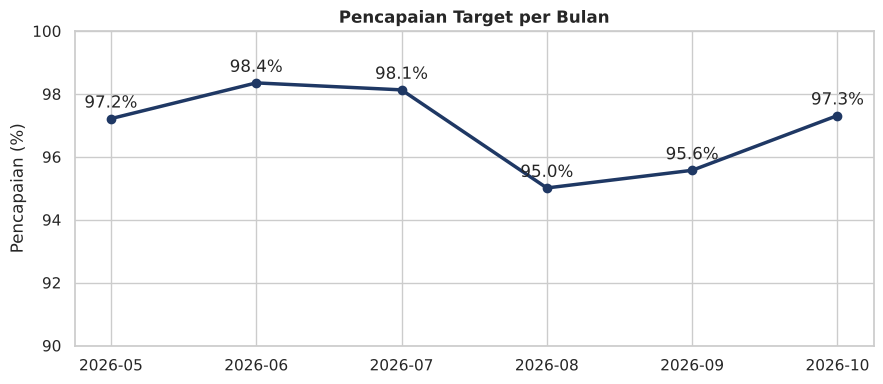

In [10]:
bulanan = df.groupby("bulan").agg(planning=("planning", "sum"), ok=("ok", "sum"))
bulanan["pencapaian"] = bulanan.ok / bulanan.planning

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(bulanan.index, bulanan.pencapaian * 100, marker="o", color=NAVY, lw=2.5)
for x, y in zip(bulanan.index, bulanan.pencapaian * 100):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_title("Pencapaian Target per Bulan", fontweight="bold")
ax.set_ylabel("Pencapaian (%)")
ax.set_ylim(90, 100)
plt.tight_layout()
plt.savefig("../images/pencapaian_bulanan.png", dpi=150)
plt.show()

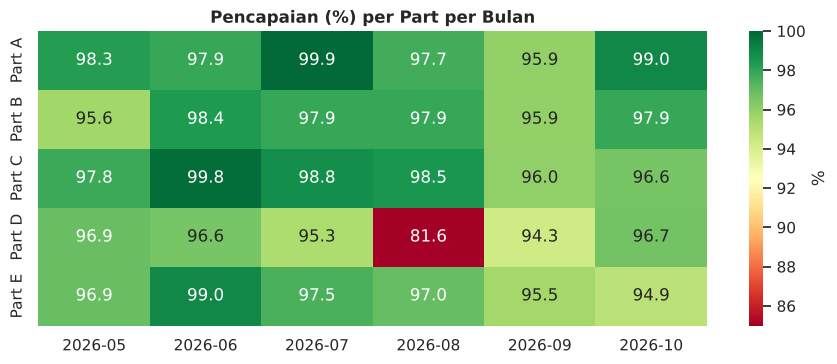

In [11]:
heat = df.pivot_table(index="part", columns="bulan", values=["ok", "planning"], aggfunc="sum")
heat = (heat["ok"] / heat["planning"] * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="RdYlGn", vmin=85, vmax=100, cbar_kws={"label": "%"}, ax=ax)
ax.set_title("Pencapaian (%) per Part per Bulan", fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../images/heatmap_part_bulan.png", dpi=150)
plt.show()

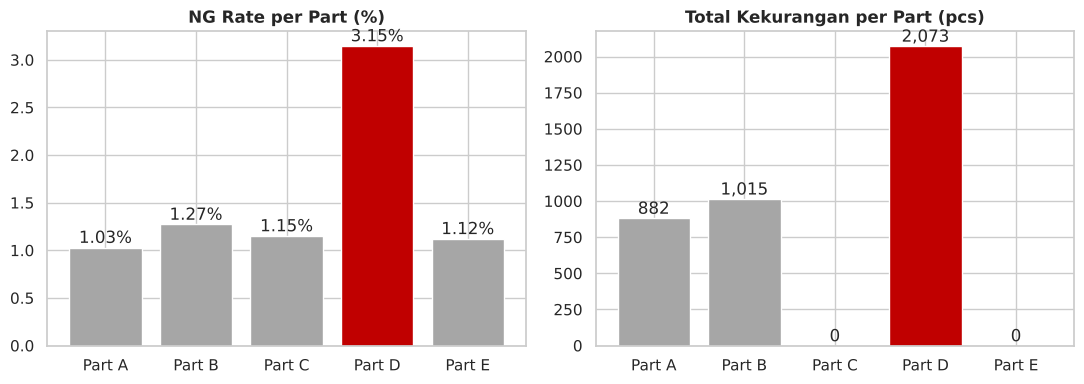

In [12]:
per_part = df.groupby("part").agg(ng=("ng", "sum"), produksi=("produksi", "sum"), kekurangan=("kekurangan", "sum"))
per_part["ng_rate"] = per_part.ng / per_part.produksi * 100
warna = ["#C00000" if p == per_part.ng_rate.idxmax() else "#A6A6A6" for p in per_part.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(per_part.index, per_part.ng_rate, color=warna)
axes[0].set_title("NG Rate per Part (%)", fontweight="bold")
for i, v in enumerate(per_part.ng_rate):
    axes[0].text(i, v + 0.05, f"{v:.2f}%", ha="center")
axes[1].bar(per_part.index, per_part.kekurangan, color=warna)
axes[1].set_title("Total Kekurangan per Part (pcs)", fontweight="bold")
for i, v in enumerate(per_part.kekurangan):
    axes[1].text(i, v + 30, f"{v:,}", ha="center")
plt.tight_layout()
plt.savefig("../images/ng_kekurangan_part.png", dpi=150)
plt.show()

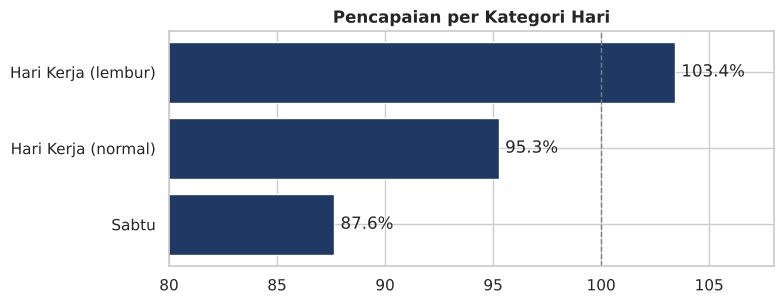

In [13]:
kat = df.groupby("kategori_hari").agg(ok=("ok", "sum"), planning=("planning", "sum"))
kat["pencapaian"] = kat.ok / kat.planning * 100
kat = kat.sort_values("pencapaian")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(kat.index, kat.pencapaian, color=NAVY)
ax.axvline(100, color="grey", ls="--", lw=1)
for i, v in enumerate(kat.pencapaian):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
ax.set_xlim(80, 108)
ax.set_title("Pencapaian per Kategori Hari", fontweight="bold")
plt.tight_layout()
plt.savefig("../images/pencapaian_tipe_hari.png", dpi=150)
plt.show()

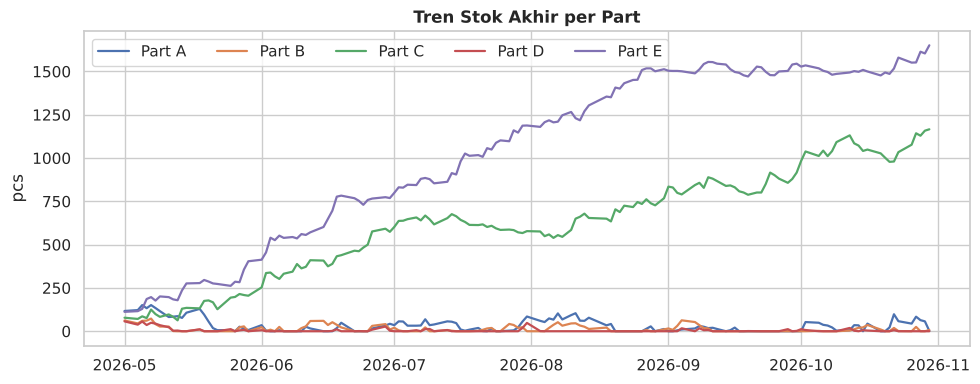

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
for part, g in df.groupby("part"):
    ax.plot(g.tanggal, g.stok_akhir, label=part, lw=1.6)
ax.set_title("Tren Stok Akhir per Part", fontweight="bold")
ax.set_ylabel("pcs")
ax.legend(ncol=5, loc="upper left")
plt.tight_layout()
plt.savefig("../images/tren_stok.png", dpi=150)
plt.show()

## 5. Insight & Rekomendasi

| # | Temuan | Rekomendasi |
|---|---|---|
| 1 | **Part D** punya NG rate ~3,1%, sekitar 3x part lain, dan kekurangan di ~68% hari kerja. | Prioritaskan perbaikan kualitas di proses Part D (cek mesin/jig, analisis jenis NG). |
| 2 | **Agustus** jadi bulan terendah karena pencapaian Part D anjlok ke ~82% (skenario masalah mesin). September juga turun, tapi merata di semua part. | Pasang alert otomatis kalau pencapaian part di bawah 90% supaya masalah ketahuan lebih cepat, bukan di akhir bulan. |
| 3 | **Lembur** menaikkan pencapaian ke >100%, sedangkan **Sabtu masuk** paling rendah (~88%). | Pakai lembur untuk part yang sedang kurang. Evaluasi efektivitas Sabtu masuk (jumlah orang, setup mesin). |
| 4 | **Part C & E** tidak pernah kurang, tapi stok terus naik sampai >1.000 pcs karena tambahan dari supplier. | Kurangi atau jadwalkan ulang order supplier untuk Part C & E supaya stok tidak menumpuk. |

**Catatan:** karena datanya simulasi, angka di atas untuk mendemonstrasikan alur analisis, bukan kondisi pabrik yang sebenarnya.